In [252]:
import pandas as pd 

df = pd.read_csv("covid19.csv")
df = df.fillna(0)
df['Date_reported'] = pd.to_datetime(df['Date_reported'])
df

,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,2020-01-05,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
1,2020-01-12,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
2,2020-01-19,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
3,2020-01-26,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
4,2020-02-02,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
...,...,...,...,...,...,...,...,...,...
58555,2024-08-04,ZW,Zimbabwe,Africa,AFRO,1.0,266387,0.0,5740
58556,2024-08-11,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58557,2024-08-18,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58558,2024-08-25,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740


<Axes: >

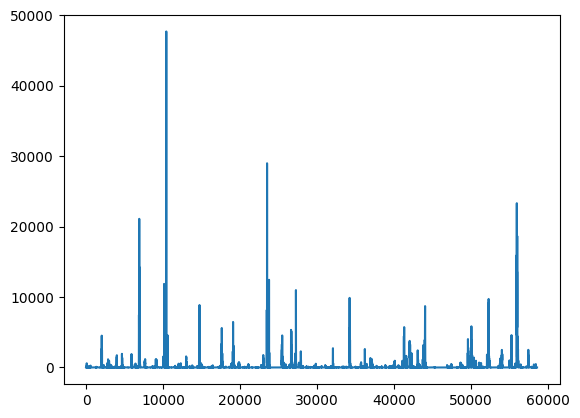

In [253]:
index = df[df["New_deaths"] < 0].index
df = df.drop(index)
df["New_deaths"].plot()

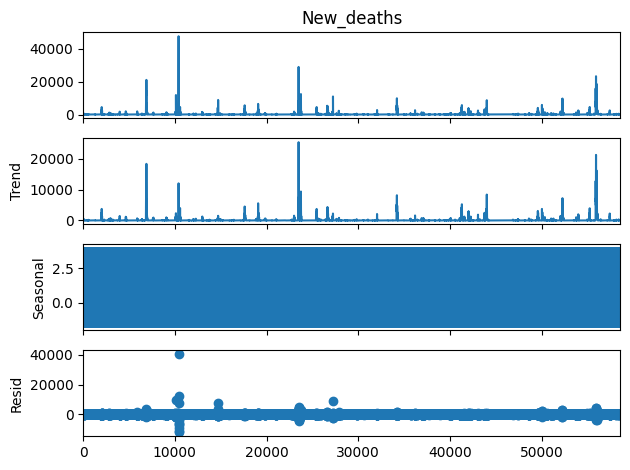

In [254]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

result = seasonal_decompose(df["New_deaths"], period=7)
result.plot()
plt.show()

Date_reported
2020-01-05       3.0
2020-01-12       1.0
2020-01-19       2.0
2020-01-26      56.0
2020-02-02     310.0
               ...  
2024-08-04    1180.0
2024-08-11    1286.0
2024-08-18    1189.0
2024-08-25    1131.0
2024-09-01     890.0
Name: New_deaths, Length: 244, dtype: float64


<Axes: xlabel='Date_reported'>

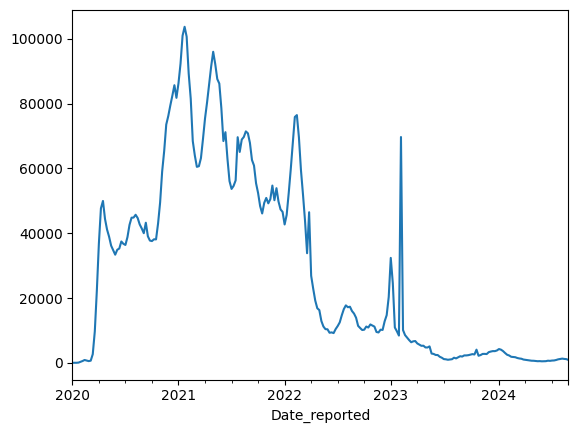

In [255]:
group = df.groupby("Date_reported")["New_deaths"].sum()
print(group)
group.plot()

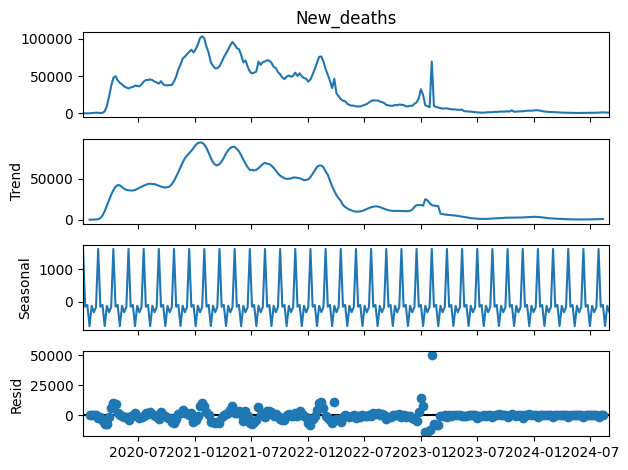

In [256]:
result = seasonal_decompose(group, period=7)
result.plot()
plt.show()

MOVING AVERAGE

In [257]:
# Moving Average (7 hari)

deaths = group.reset_index()
deaths["Moving_avg"] = deaths["New_deaths"].rolling(window=7).mean()
deaths[["New_deaths", "Moving_avg"]].head(10)

,New_deaths,Moving_avg
0,3.0,NaN
1,1.0,NaN
2,2.0,NaN
3,56.0,NaN
4,310.0,NaN
5,545.0,NaN
6,864.0,254.428571
7,692.0,352.857143
8,519.0,426.857143
9,650.0,519.428571


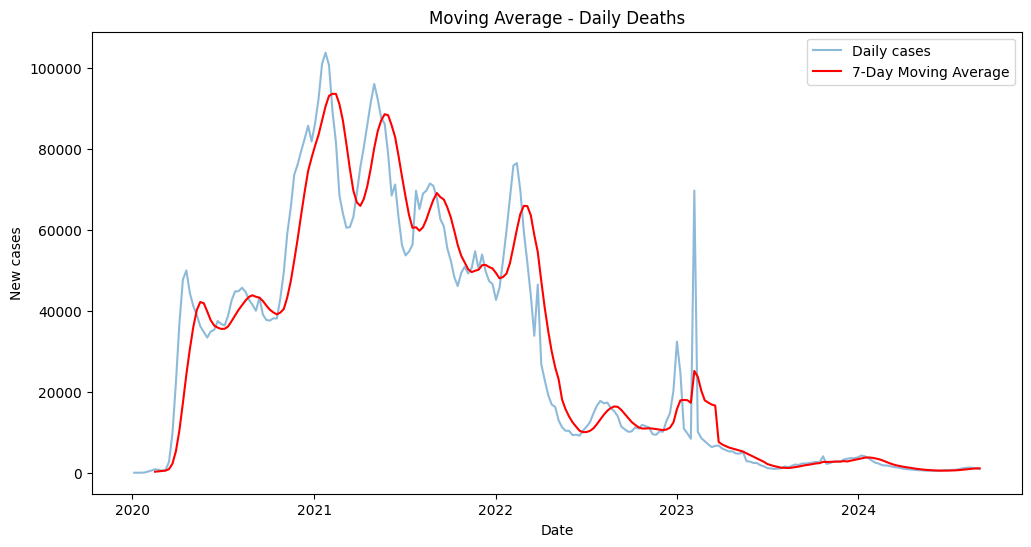

In [258]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.lineplot(x = group.index, y = group.values, label='Daily cases', alpha=0.5)
sns.lineplot(x = deaths["Date_reported"], y = deaths["Moving_avg"], label='7-Day Moving Average', color='red')
plt.title('Moving Average - Daily Deaths')
plt.xlabel('Date')
plt.ylabel('New cases')
plt.legend()
plt.show()

EXPONENTIAL SMOOTHING

In [259]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

single = ExponentialSmoothing(group.values, trend=None, seasonal=None).fit()
double = ExponentialSmoothing(group.values, trend='add', seasonal=None).fit()
triple = ExponentialSmoothing(group.values, trend='add', seasonal="add", seasonal_periods=7).fit()

exponential = pd.DataFrame({
    "Single" : single.fittedvalues,
    "Double" : double.fittedvalues,
    "Triple" : triple.fittedvalues,
})

exponential.head()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


,Single,Double,Triple
0,-154.400000,-60.109091,-2268.241651
1,-19.530163,88.055322,2035.483898
2,-1.938678,108.036252,-22.796122
3,1.436219,111.806551,1647.811295
4,48.189766,158.446724,1502.700899


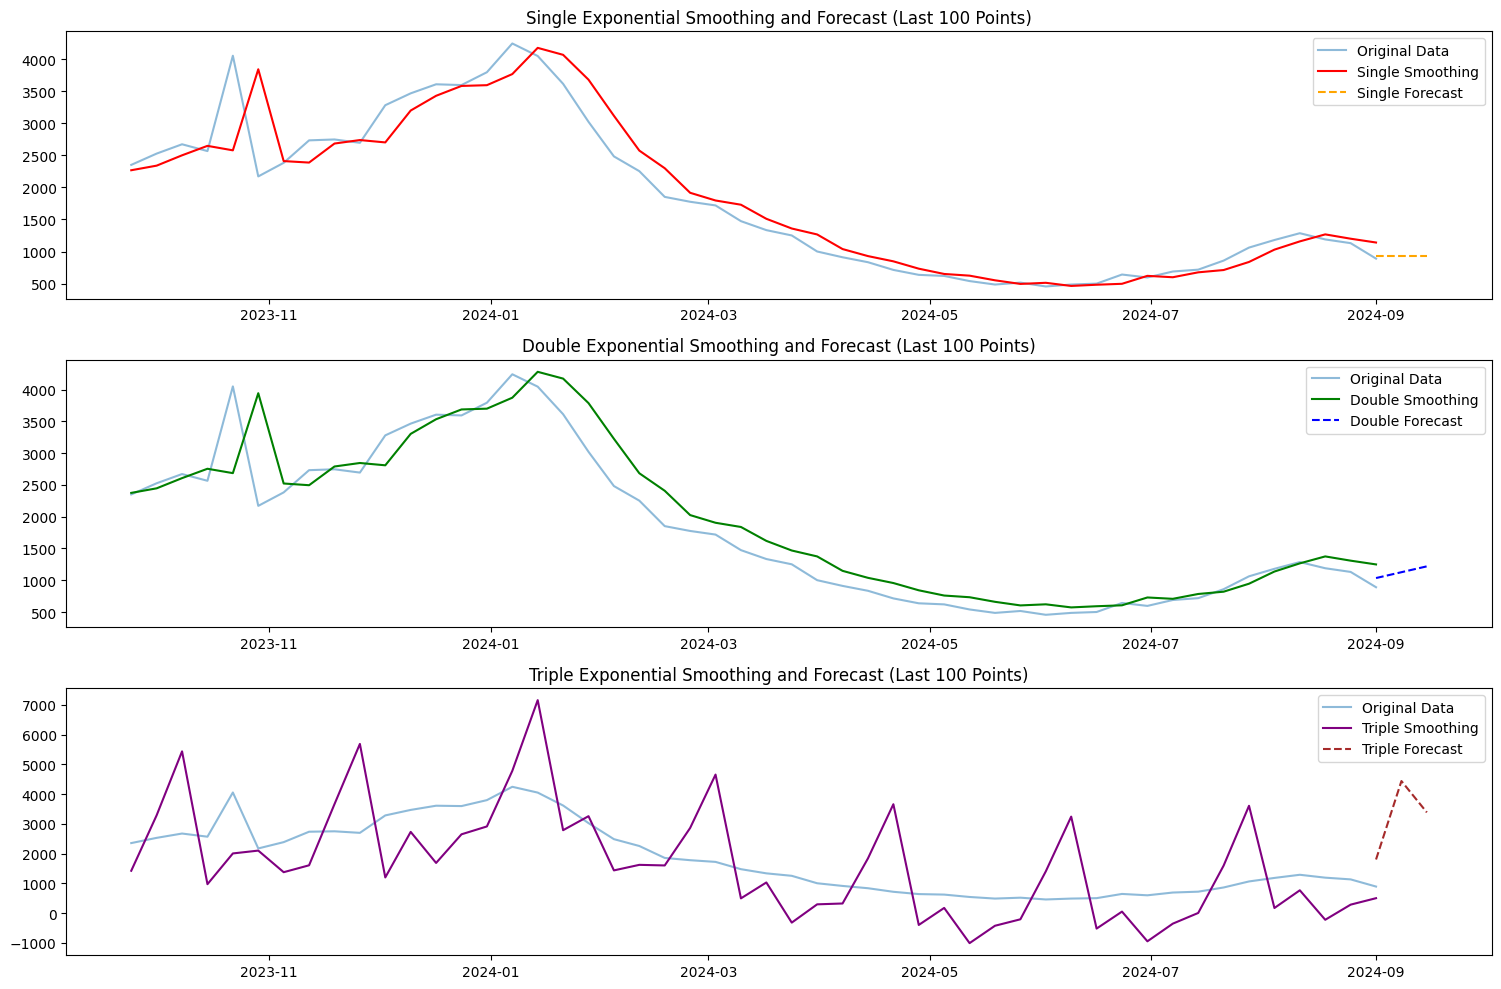

In [260]:
week = 3
single_forecast = single.forecast(steps=week)
double_forecast = double.forecast(steps=week)
triple_forecast = triple.forecast(steps=week)

data = 50  
group_tail = group.tail(data)
index_future = pd.date_range(start=group.index[-1], periods=week, freq='W')

plt.figure(figsize=(15, 10))

# Plot Single Exponential Smoothing
plt.subplot(3, 1, 1)
plt.plot(group_tail.index, group_tail.values, label="Original Data", alpha=0.5)
plt.plot(group_tail.index, single.fittedvalues[-data:], label="Single Smoothing", color='red')
plt.plot(index_future, single_forecast, label="Single Forecast", linestyle="--", color='orange')
plt.title("Single Exponential Smoothing and Forecast (Last 100 Points)")
plt.legend()

# Plot Double Exponential Smoothing
plt.subplot(3, 1, 2)
plt.plot(group_tail.index, group_tail.values, label="Original Data", alpha=0.5)
plt.plot(group_tail.index, double.fittedvalues[-data:], label="Double Smoothing", color='green')
plt.plot(index_future, double_forecast, label="Double Forecast", linestyle="--", color='blue')
plt.title("Double Exponential Smoothing and Forecast (Last 100 Points)")
plt.legend()

# Plot Triple Exponential Smoothing
plt.subplot(3, 1, 3)
plt.plot(group_tail.index, group_tail.values, label="Original Data", alpha=0.5)
plt.plot(group_tail.index, triple.fittedvalues[-data:], label="Triple Smoothing", color='purple')
plt.plot(index_future, triple_forecast, label="Triple Forecast", linestyle="--", color='brown')
plt.title("Triple Exponential Smoothing and Forecast (Last 100 Points)")
plt.legend()

plt.tight_layout()
plt.show()

ARIMA

In [261]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
group_diff = df.groupby("Date_reported")[["New_deaths", "New_cases"]].sum()
group_diff.index.freq = "W"

In [262]:
from statsmodels.tsa.stattools import adfuller

adf_cases = adfuller(group_diff["New_cases"])
adf_deaths = adfuller(group_diff["New_deaths"])
print('p-value new cases:', adf_cases[1])
print('p-value new deaths:', adf_deaths[1])

p-value new cases: 0.49803224825450915


In [ ]:
diff = 6
group_diff['New_deaths_diff'] = group_diff['New_deaths'].diff(diff)
group_diff = group_diff.fillna(0)
result = adfuller(group_diff['New_deaths_diff'])
print('p-value new deaths:', result[1])

In [ ]:
def diff_convert(data, parameter, len_diff):
    reconstructed = list(group['New_deaths'][:len_diff]) 
    for i in range(diff, len(parameter)):
        reconstructed.append(abs(reconstructed[i - len_diff] + data.iloc[i]))

    return reconstructed

In [ ]:
len_train = int(len(group) * 0.8)
train = group_diff[:len_train]
test = group_diff[len_train:]

In [265]:
auto = auto_arima(train["New_deaths_diff"], 
                  suppress_warnings=True, 
                  error_action="ignore", 
                  stepwise = True)

p, d, q = auto.order

model = ARIMA(train["New_deaths_diff"], order=(p, d, q))
model_fit = model.fit()

start = 0
end = len(train) - 1

prediction = model_fit.predict(start, end)

reconstructed = list(group_diff['New_deaths'][:diff]) 
for i in range(diff, len(group_diff)):
    reconstructed.append(abs(reconstructed[i - diff] + train["New_deaths_diff"].iloc[i]))

reconstructed.plot()
train["New_deaths_diff"].plot(label = "Train actual", legend = True)
# prediction.plot(label = "Train predict", legend = True)

IndexError: single positional indexer is out-of-bounds

<Axes: >

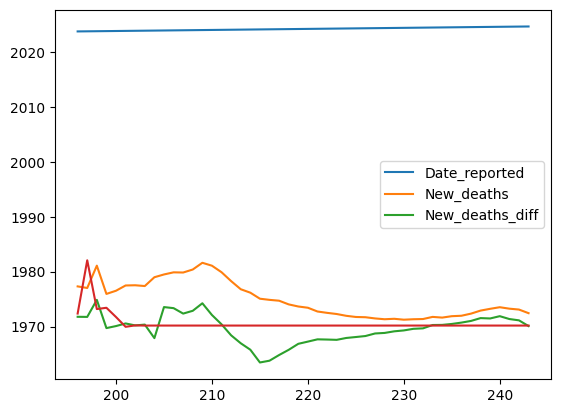

In [207]:
forecast = model_fit.forecast(len(test))

test.plot()
forecast.plot()

In [208]:
index_forecast = pd.date_range(start=group.index[-1], periods=len(forecast) + 1, freq="W")[1:]
index_forecast

DatetimeIndex(['1970-01-11 00:00:00.000000243',
               '1970-01-18 00:00:00.000000243',
               '1970-01-25 00:00:00.000000243',
               '1970-02-01 00:00:00.000000243',
               '1970-02-08 00:00:00.000000243',
               '1970-02-15 00:00:00.000000243',
               '1970-02-22 00:00:00.000000243',
               '1970-03-01 00:00:00.000000243',
               '1970-03-08 00:00:00.000000243',
               '1970-03-15 00:00:00.000000243',
               '1970-03-22 00:00:00.000000243',
               '1970-03-29 00:00:00.000000243',
               '1970-04-05 00:00:00.000000243',
               '1970-04-12 00:00:00.000000243',
               '1970-04-19 00:00:00.000000243',
               '1970-04-26 00:00:00.000000243',
               '1970-05-03 00:00:00.000000243',
               '1970-05-10 00:00:00.000000243',
               '1970-05-17 00:00:00.000000243',
               '1970-05-24 00:00:00.000000243',
               '1970-05-31 00:00:00.0000

SARIMA

In [209]:
group_sarima = df.groupby("Date_reported")[["New_deaths", "New_cases"]].sum()

group_sarima.index.freq = "W"
len_train = int(len(group_sarima) * 0.8)
train = group_sarima[:len_train]
test = group_sarima[len_train:]

In [210]:
# diff = 6
# group['New_deaths_diff'] = group['New_deaths'].diff(diff)
# result = adfuller(group['New_deaths_diff'].dropna())
# print('p-value new deaths:', result[1])

In [211]:
# Membagi data menjadi train dan test
# group_diff = group.iloc[diff:]
# len_train = int(len(group) * 0.8)
# train = group_diff[:len_train]
# test = group_diff[len_train:]

In [212]:
# def diff_convert(data, parameter):
#     reconstructed = list(group['New_deaths'][:diff]) 
#     for i in range(diff, len(parameter)):
#         reconstructed.append(abs(reconstructed[i - diff] + data.iloc[i]))

#     return reconstructed

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[4] intercept   : AIC=4028.925, Time=0.16 sec
 ARIMA(0,1,0)(0,0,0)[4] intercept   : AIC=4026.236, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[4] intercept   : AIC=4024.770, Time=0.02 sec
 ARIMA(0,1,1)(0,0,1)[4] intercept   : AIC=4025.703, Time=0.02 sec
 ARIMA(0,1,0)(0,0,0)[4]             : AIC=4024.239, Time=0.01 sec
 ARIMA(0,1,0)(1,0,0)[4] intercept   : AIC=4028.231, Time=0.01 sec
 ARIMA(0,1,0)(0,0,1)[4] intercept   : AIC=4028.230, Time=0.01 sec
 ARIMA(0,1,0)(1,0,1)[4] intercept   : AIC=4030.166, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[4] intercept   : AIC=4022.789, Time=0.01 sec
 ARIMA(1,1,0)(0,0,1)[4] intercept   : AIC=4024.766, Time=0.01 sec
 ARIMA(1,1,0)(1,0,1)[4] intercept   : AIC=4026.552, Time=0.02 sec
 ARIMA(2,1,0)(0,0,0)[4] intercept   : AIC=4023.380, Time=0.01 sec
 ARIMA(1,1,1)(0,0,0)[4] intercept   : AIC=4023.788, Time=0.01 sec
 ARIMA(0,1,1)(0,0,0)[4] intercept   : AIC=4023.723, Time=0.01 sec
 ARIMA(2,1,1)(0,0,0)[4] intercept

<Axes: xlabel='Date_reported'>

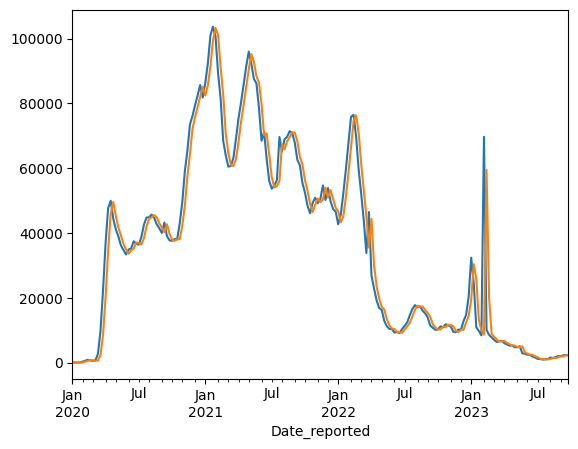

In [213]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima
import pandas as pd
import matplotlib.pyplot as plt

auto = auto_arima(
    train["New_deaths"],
    seasonal=True,              
    m=4,                        
    trace=True,
    suppress_warnings=True,
    stepwise=True
)

p, d, q = auto.order
P, D, Q, s = auto.seasonal_order

model = SARIMAX(
    train['New_deaths'],
    order=(p, d, q),
    seasonal_order=(P, D, Q, s),
    enforce_stationarity=False,
    enforce_invertibility=False
)
model_fit = model.fit(method="powell")

predictions = model_fit.predict(start=0, end=len(train) - 1)

train["New_deaths"].plot()
predictions.plot()

<Axes: xlabel='Date_reported'>

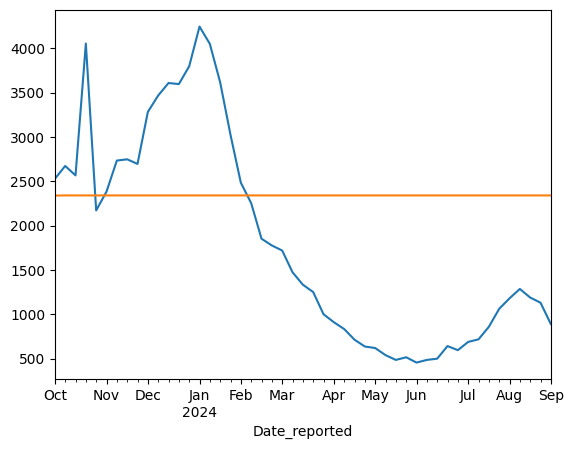

In [214]:
forecast = model_fit.forecast(steps = len(test))

test["New_deaths"].plot()
forecast.plot()

In [215]:
# reconstructed = diff_convert(predictions, train)

# comparison = pd.DataFrame({
#     'Original': train['New_deaths'], 
#     'Reconstructed': reconstructed  
# }, index=train.index)

# comparison.plot()

In [216]:
# forecast = model_fit.forecast(steps = len(test))

# reconstructed = diff_convert(forecast, test)

# comparison = pd.DataFrame({
#     'Original': test['New_deaths'], 
#     'Reconstructed': reconstructed  
# }, index=test.index)

# comparison.plot()

SARIMA Exogenous

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[4] intercept   : AIC=4028.925, Time=0.16 sec
 ARIMA(0,1,0)(0,0,0)[4] intercept   : AIC=4026.236, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[4] intercept   : AIC=4024.770, Time=0.01 sec
 ARIMA(0,1,1)(0,0,1)[4] intercept   : AIC=4025.703, Time=0.02 sec
 ARIMA(0,1,0)(0,0,0)[4]             : AIC=4024.239, Time=0.00 sec
 ARIMA(0,1,0)(1,0,0)[4] intercept   : AIC=4028.231, Time=0.02 sec
 ARIMA(0,1,0)(0,0,1)[4] intercept   : AIC=4028.230, Time=0.02 sec
 ARIMA(0,1,0)(1,0,1)[4] intercept   : AIC=4030.166, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[4] intercept   : AIC=4022.789, Time=0.01 sec
 ARIMA(1,1,0)(0,0,1)[4] intercept   : AIC=4024.766, Time=0.01 sec
 ARIMA(1,1,0)(1,0,1)[4] intercept   : AIC=4026.552, Time=0.02 sec
 ARIMA(2,1,0)(0,0,0)[4] intercept   : AIC=4023.380, Time=0.01 sec
 ARIMA(1,1,1)(0,0,0)[4] intercept   : AIC=4023.788, Time=0.01 sec
 ARIMA(0,1,1)(0,0,0)[4] intercept   : AIC=4023.723, Time=0.01 sec
 ARIMA(2,1,1)(0,0,0)[4] intercept

<Axes: xlabel='Date_reported'>

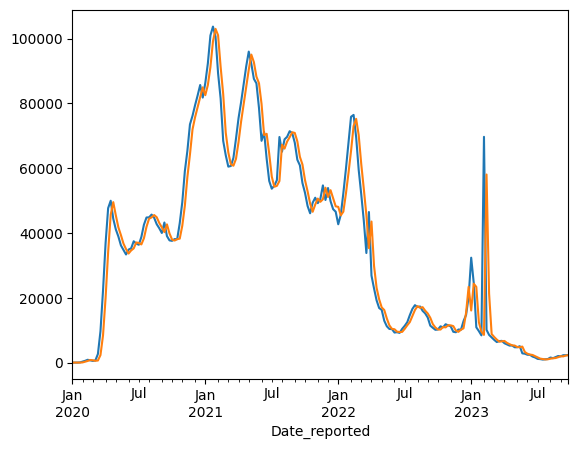

In [217]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima
import pandas as pd
import matplotlib.pyplot as plt

auto = auto_arima(
    train["New_deaths"],
    exogenous=train['New_cases'],  
    seasonal=True,              
    m=4,                        
    trace=True,
    suppress_warnings=True,
    stepwise=True
)

p, d, q = auto.order
P, D, Q, s = auto.seasonal_order

model = SARIMAX(
    train['New_deaths'],
    exog=train['New_cases'],
    order=(p, d, q),
    seasonal_order=(P, D, Q, s),
    enforce_stationarity=False,
    enforce_invertibility=False
)
model_fit = model.fit(method="powell")

predictions = model_fit.predict(start=0, end=len(train) - 1, exog=train["New_cases"])

train["New_deaths"].plot()
predictions.plot()

<Axes: xlabel='Date_reported'>

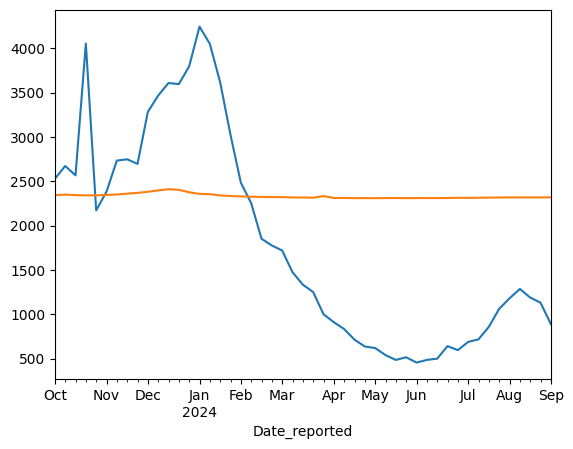

In [218]:
forecast = model_fit.forecast(steps = len(test), exog = test["New_cases"])

test["New_deaths"].plot()
forecast.plot()

In [219]:
# reconstructed = diff_convert(predictions, train)

# comparison = pd.DataFrame({
#     'Original': train['New_deaths'], 
#     'Reconstructed': reconstructed  
# }, index=train.index)

# comparison.plot()

In [220]:
# forecast = model_fit.forecast(steps=len(test), exog=test['New_cases'])

# reconstructed = diff_convert(forecast, test)

# comparison = pd.DataFrame({
#     'Original': test['New_deaths'], 
#     'Reconstructed': reconstructed  
# }, index=test.index)

# comparison.plot()